# Введение в машинное обучение

## 1. Intro

### Примеры применения машинного обучения

1. **Фильтрация спама в электронной почте.**
   Модель анализирует текст, тему письма и сведения об отправителе, чтобы определить, является ли письмо спамом.
   Польза: сокращает количество нежелательных писем и экономит время пользователя.
   Тип задачи: бинарная классификация - «спам» или «не спам».

2. **Прогнозирование стоимости автомобиля.**
   Модель получает марку, модель, год выпуска, пробег и другие характеристики автомобиля и предсказывает его стоимость.
   Польза: помогает покупателям и продавцам оценить справедливую цену.
   Тип задачи: регрессия - предсказание числового значения.

3. **Распознавание рукописных цифр.**
   Модель получает изображение одной цифры и определяет, какая цифра на нём изображена.
   Польза: позволяет автоматизировать обработку анкет и документов.
   Тип задачи: многоклассовая классификация - один из десяти классов от 0 до 9.

4. **Сегментация покупателей магазина.**
   Модель анализирует частоту покупок, суммы заказов и предпочтения покупателей и объединяет похожих покупателей в группы.
   Польза: помогает создавать предложения для разных групп клиентов.
   Тип задачи: кластеризация - поиск групп без заранее заданных правильных ответов.

5. **Поиск товаров, которые часто покупают вместе.**
   Модель анализирует состав покупок и находит устойчивые сочетания товаров.
   Польза: помогает магазину рекомендовать сопутствующие товары и планировать их размещение.
   Тип задачи: поиск ассоциативных правил - выявление совместной встречаемости товаров.

### Типы задач из таблицы задания

Тип задачи зависит от того, что именно требуется предсказать и какие данные доступны.

| № | Задача | Возможная постановка |
|---|--------|----------------------|
| 1 | Предсказать стоимость жилья | Регрессия: предсказываем числовую цену. |
| 2 | Определить, вернёт ли клиент кредит | Бинарная классификация: вернёт или не вернёт. |
| 3 | Предсказать время приёма лекарства | Регрессия, если предсказываем время до следующего приёма. |
| 4 | Выбрать лекарство из доступных | Многоклассовая классификация, если каждому примеру соответствует одно правильное лекарство. |
| 5 | Выбрать клиентов для рекламной рассылки | Бинарная классификация, если предсказываем отклик клиента. Кластеризация, если сначала ищем группы похожих клиентов. |
| 6 | Определить брак по фотографии изделия | Бинарная классификация: изделие бракованное или исправное. |
| 7 | Выбрать расположение товаров на полках | Задача оптимизации. Можно использовать регрессию для прогнозирования продаж при разных вариантах размещения и выбирать лучший вариант. |
| 8 | Найти сайты по текстовому запросу | Ранжирование: упорядочиваем сайты по соответствию запросу. |
| 9 | Разделить покупателей на группы | Кластеризация: объединяем покупателей по сходству характеристик и поведения. |
| 10 | Обнаружить аномалии в трафике сайта | Обнаружение аномалий без учителя, если меток атак нет; бинарная классификация, если примеры атак и обычного трафика размечены. |

Некоторые задачи допускают несколько подходов. Например, историю покупок можно использовать для поиска ассоциативных правил, а снижение размерности - для визуализации множества характеристик покупателей.

### Разница между multiclass и multilabel

**Multiclass - многоклассовая классификация.**
Есть больше двух классов, и каждому объекту присваивается ровно один из них.

Пример: модель распознаёт одну рукописную цифру на изображении.
Возможные классы - от 0 до 9. Правильный ответ - только одна цифра.

**Multilabel - многометочная классификация.**
Каждому объекту может соответствовать несколько меток одновременно.

Пример: модель определяет объекты на фотографии.
На одном изображении могут одновременно присутствовать человек, автомобиль и собака, поэтому ему присваиваются все три метки.

Главное различие: в multiclass выбирается один класс из нескольких, а в multilabel - набор подходящих меток.

### Прогнозирование цены жилья: регрессия или классификация?

Предсказание цены жилья - задача регрессии, поскольку результатом является числовое значение стоимости.

Эту задачу можно преобразовать в классификацию, если разделить цены на интервалы. Например:

- класс 0: менее 5 млн рублей;
- класс 1: от 5 млн рублей включительно до 10 млн рублей не включительно;
- класс 2: от 10 млн рублей.

Тогда модель будет предсказывать ценовую категорию жилья.

При таком преобразовании теряется точность ответа: мы узнаём диапазон цены, но не конкретную стоимость. Такой подход подходит, если для решения задачи достаточно определить ценовую категорию.

## 2. Первичный анализ данных

In [120]:
%pip install pandas numpy scikit-learn lightgbm scipy statsmodels matplotlib seaborn

76014.84s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [121]:
import pandas as pd
import numpy as np
import sklearn
import lightgbm as lgb
import scipy
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeRegressor

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from IPython.display import display

%matplotlib inline

In [122]:
df = pd.read_json('./data/train.json')
df.head()

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium
10,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,5ba989232d0489da1b5f2c45f6688adc,[https://photos.renthop.com/2/7211212_1ed4542e...,3000,792 Metropolitan Avenue,medium
15,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,7225292,-73.9743,2c3b41f588fbb5234d8a1e885a436cfa,[https://photos.renthop.com/2/7225292_901f1984...,2795,340 East 34th Street,low


In [123]:
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")
print("Столбцы:", df.columns.tolist())

Количество строк: 49352
Количество столбцов: 15
Столбцы: ['bathrooms', 'bedrooms', 'building_id', 'created', 'description', 'display_address', 'features', 'latitude', 'listing_id', 'longitude', 'manager_id', 'photos', 'price', 'street_address', 'interest_level']


### Размер данных и целевая переменная

Датасет содержит 49 352 строки и 15 столбцов.
Каждая строка соответствует одному объявлению об аренде квартиры.

Целевая переменная - `price`, стоимость аренды, которую мы будем предсказывать.

Для обучения моделей по заданию будем использовать признаки:
- `bathrooms` - количество ванных комнат;
- `bedrooms` - количество спален.

In [124]:
df.info()

<class 'pandas.DataFrame'>
Index: 49352 entries, 4 to 124009
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  str    
 3   created          49352 non-null  str    
 4   description      49352 non-null  str    
 5   display_address  49352 non-null  str    
 6   features         49352 non-null  object 
 7   latitude         49352 non-null  float64
 8   listing_id       49352 non-null  int64  
 9   longitude        49352 non-null  float64
 10  manager_id       49352 non-null  str    
 11  photos           49352 non-null  object 
 12  price            49352 non-null  int64  
 13  street_address   49352 non-null  str    
 14  interest_level   49352 non-null  str    
dtypes: float64(3), int64(3), object(2), str(7)
memory usage: 6.0+ MB


### Структура данных

Таблица содержит 49 352 строки и 15 столбцов.
По результатам `info()` пропусков, распознаваемых pandas, нет.
Полностью пустых столбцов нет.

Основные столбцы имеют следующие типы:
- `price` - int64, целочисленная стоимость аренды;
- `bathrooms` - float64, количество ванных комнат;
- `bedrooms` - int64, количество спален;
- `interest_level` - str, строковый признак, обозначающий категорию интереса к объявлению.

Отсутствие пропусков по `info()` не исключает наличия пустых строк или пустых списков - для их обнаружения нужна отдельная проверка.

In [125]:
df.describe()

,bathrooms,bedrooms,latitude,listing_id,longitude,price
count,49352.00000,49352.000000,49352.000000,4.935200e+04,49352.000000,4.935200e+04
mean,1.21218,1.541640,40.741545,7.024055e+06,-73.955716,3.830174e+03
std,0.50142,1.115018,0.638535,1.262746e+05,1.177912,2.206687e+04
min,0.00000,0.000000,0.000000,6.811957e+06,-118.271000,4.300000e+01
25%,1.00000,1.000000,40.728300,6.915888e+06,-73.991700,2.500000e+03
50%,1.00000,1.000000,40.751800,7.021070e+06,-73.977900,3.150000e+03
75%,1.00000,2.000000,40.774300,7.128733e+06,-73.954800,4.100000e+03
max,10.00000,8.000000,44.883500,7.753784e+06,0.000000,4.490000e+06


### Основные статистики

Средняя стоимость аренды составляет около 3 830,17, медианная - 3 150.
Среднее выше медианы, что указывает на влияние дорогих объявлений.

Минимальная цена - 43, максимальная - 4 490 000.
При этом половина объявлений имеет цену от 2 500 до 4 100 - между первым и третьим квартилями.

Большой разрыв между максимальной ценой и третьим квартилем указывает на возможные выбросы. Для их дальнейшего исследования построим гистограмму и boxplot.

Количество спален изменяется от 0 до 8, количество ванных комнат - от 0 до 10.
Нулевое число спален может соответствовать студии и само по себе не означает ошибку.

In [126]:
df.corr(numeric_only=True)

,bathrooms,bedrooms,latitude,listing_id,longitude,price
bathrooms,1.000000,0.533446,-0.009657,0.000776,0.010393,0.069661
bedrooms,0.533446,1.000000,-0.004745,0.011968,0.006892,0.051788
latitude,-0.009657,-0.004745,1.000000,0.001712,-0.966807,-0.000707
listing_id,0.000776,0.011968,0.001712,1.000000,-0.000907,0.008090
longitude,0.010393,0.006892,-0.966807,-0.000907,1.000000,-0.000087
price,0.069661,0.051788,-0.000707,0.008090,-0.000087,1.000000


### Корреляции исходных числовых признаков

Для числовых столбцов рассчитана корреляция Пирсона.
Корреляция `price` с `bathrooms` составляет около 0,070, а с `bedrooms` - около 0,052.
В исходных данных линейная связь этих признаков с ценой слабая.
При этом `bathrooms` и `bedrooms` имеют умеренную положительную корреляцию около 0,533.

Слабая корреляция не доказывает отсутствия зависимости: связь может быть нелинейной, а на коэффициент могут влиять экстремальные значения цены.
После удаления выбросов повторно исследуем корреляции.

Столбец `listing_id` является идентификатором объявления. Его числовой тип сам по себе не делает его содержательным признаком для модели.


In [127]:
data = df[["bathrooms", "bedrooms", "interest_level", "price"]].copy()
print(data.shape)

(49352, 4)


In [128]:
data.head(5)

,bathrooms,bedrooms,interest_level,price
4,1.0,1,medium,2400
6,1.0,2,low,3800
9,1.0,2,medium,3495
10,1.5,3,medium,3000
15,1.0,0,low,2795


## 3. Статистический анализ данных

### Распределение целевой переменной

Исследуем распределение стоимости аренды `price` с помощью гистограммы и boxplot.
Гистограмма разбивает значения на интервалы и показывает, сколько объявлений попадает в каждый интервал.
На первом шаге используем все строки таблицы `data`, чтобы увидеть исходный диапазон цен.


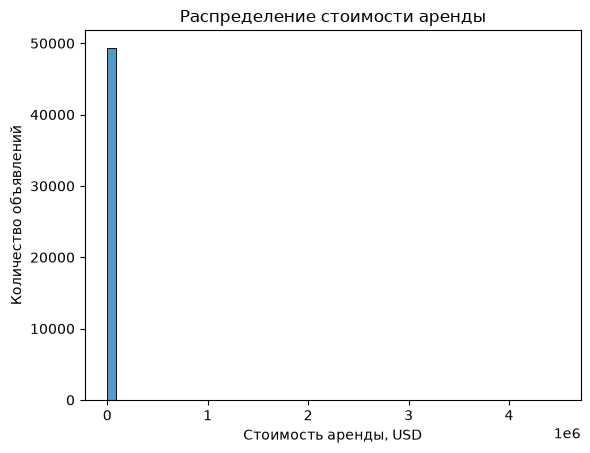

In [129]:
sns.histplot(
    data=data,
    x=data["price"],
    bins=50
)

plt.title("Распределение стоимости аренды")
plt.xlabel("Стоимость аренды, USD")
plt.ylabel("Количество объявлений")
plt.show()

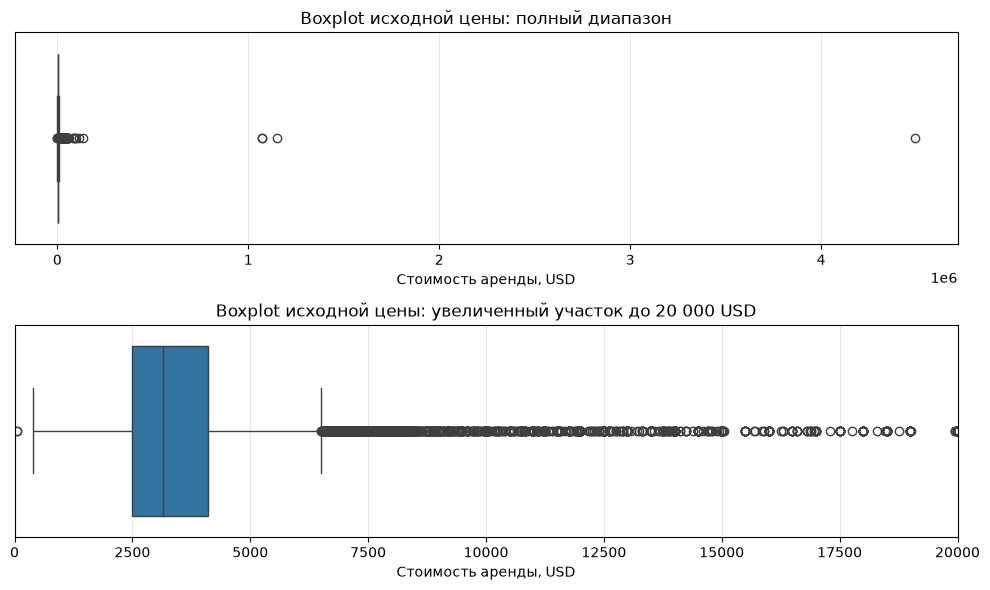

In [130]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

for ax in axes:
    sns.boxplot(data=data, x="price", ax=ax)
    ax.set_xlabel("Стоимость аренды, USD")
    ax.set_ylabel("")
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.3)

axes[0].set_title("Boxplot исходной цены: полный диапазон")
axes[1].set_title("Boxplot исходной цены: увеличенный участок до 20 000 USD")
axes[1].set_xlim(0, 20000)

plt.tight_layout()
plt.show()


### Вывод по boxplot исходной цены

Медианная цена составляет 3 150 USD. Центральная половина объявлений находится между 2 500 и 4 100 USD.
На графике полного диапазона ящик сжат из-за экстремально высоких цен, достигающих 4 490 000 USD.
На увеличенном участке видны ящик, медиана и точки за усами.

Оба графика построены по исходной таблице `data`. Во втором графике изменены только видимые границы оси X, строки из данных не удалялись.
Точки за усами являются потенциальными выбросами, но сами по себе не доказывают ошибку в объявлении.
Для дальнейшей очистки используем 1-й и 99-й процентили, как указано в задании; они отличаются от границ усов boxplot.


### Вывод по исходной гистограмме

На гистограмме почти все объявления сосредоточены в первом интервале.
Максимальная цена составляет 4 490 000, поэтому при 50 интервалах ширина каждого интервала составляет около 89 800.
Обычные для этого датасета цены в несколько тысяч попадают в один интервал, и подробная форма распределения не видна.

Такой вид графика связан с экстремальными значениями цены.
Сначала дополнительно исследуем их с помощью boxplot, затем по условию задания оставим цены в пределах 1-го и 99-го процентилей и повторно построим гистограмму.


In [131]:
lower = data["price"].quantile(0.01)
upper = data["price"].quantile(0.99)
print(lower, upper)

#Создаем новый датасет удаляя из него выбросы
data_clean = data[data["price"].between(lower,upper)].copy()


1475.0 13000.0


In [132]:
print(f"Количество строк до очистки: {len(data)}")
print(f"Количество строк после очистки: {len(data_clean)}")
print(f"Удалено строк: {len(data) - len(data_clean)}")


Количество строк до очистки: 49352
Количество строк после очистки: 48379
Удалено строк: 973


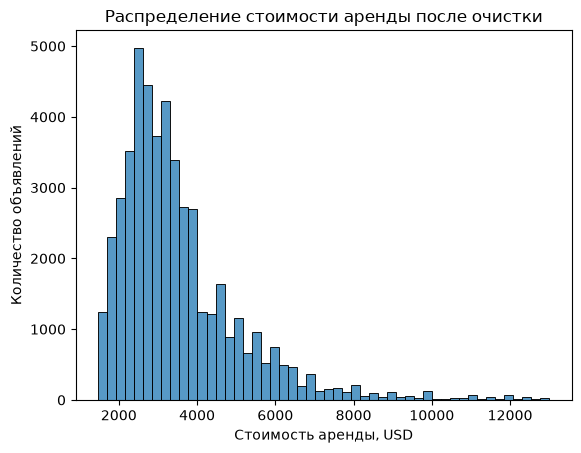

In [133]:
sns.histplot(
    data=data_clean,
    x=data_clean["price"],
    bins=50
)

plt.title("Распределение стоимости аренды после очистки")
plt.xlabel("Стоимость аренды, USD")
plt.ylabel("Количество объявлений")
plt.show()

### Вывод по гистограмме после очистки

После фильтрации остались объявления с ценами от 1 475 до 13 000 USD включительно.
В таблице `data_clean` содержится 48 379 строк и 4 столбца. Удалено 973 объявления, около 1,97% исходной выборки.

Теперь форма распределения хорошо видна: наибольшая концентрация объявлений наблюдается в районе 2 000-4 000 USD.
Распределение асимметрично, с длинным правым хвостом: дорогие объявления встречаются реже, но сохраняются после очистки.
Удаление крайних значений сделало основную часть распределения различимой при тех же 50 интервалах гистограммы.

Дальнейшие этапы анализа и обучения выполняем на очищенной выборке. Исходную таблицу `data` сохраняем для сравнения.


In [134]:
print(data_clean["interest_level"].dtype)
data_clean["interest_level"].value_counts()

str


interest_level
low       33697
medium    11116
high       3566
Name: count, dtype: int64

### Тип и значения признака interest_level

Столбец `interest_level` имеет строковый тип `str` и содержит три категории уровня интереса к объявлению.
По смыслу это упорядоченный категориальный признак: low, medium, high.

| Категория | Количество объявлений | Доля |
|---|---:|---:|
| `low` | 33 697 | 69,65% |
| `medium` | 11 116 | 22,98% |
| `high` | 3 566 | 7,37% |

Всего 48 379 объявлений. Распределение категорий неравномерно: чаще всего встречается низкий уровень интереса, реже всего высокий.
В этом проекте целевая переменная - `price`; `interest_level` исследуем как признак.


In [135]:
interest_dict = {
    "low": 0,
    "medium": 1,
    "high": 2
}

data_clean["interest_level_encoded"] = data_clean["interest_level"].map(lambda x: interest_dict[x])
print(data_clean["interest_level_encoded"].isna().sum())

0


In [136]:
data_clean["interest_level_encoded"].value_counts()

interest_level_encoded
0    33697
1    11116
2     3566
Name: count, dtype: int64

In [137]:
data_clean["interest_level_encoded"].dtype

dtype('int64')

### Кодирование уровня интереса

Создан числовой столбец `interest_level_encoded` со следующим соответствием:
- low: 0;
- medium: 1;
- high: 2.

Количество объявлений каждой категории сохранилось: 33 697 для значения 0, 11 116 для значения 1 и 3 566 для значения 2.
После кодирования пропусков в новом столбце нет.
Исходные строковые категории доступны в столбце `interest_level`.

Кодирование отражает порядок уровней интереса. Одинаковая числовая разница между соседними кодами не доказывает одинаковую разницу в фактическом интересе к объявлениям.


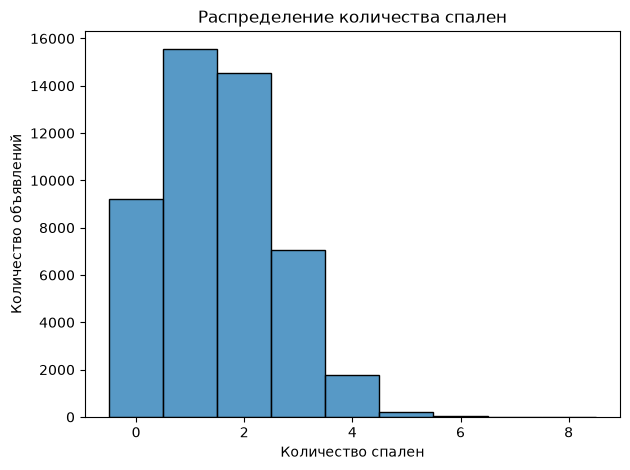

In [138]:
sns.histplot(
    data=data_clean,
    x="bedrooms",
    discrete=True    
)

plt.title("Распределение количества спален")
plt.xlabel("Количество спален")
plt.ylabel("Количество объявлений")
plt.tight_layout()
plt.show()


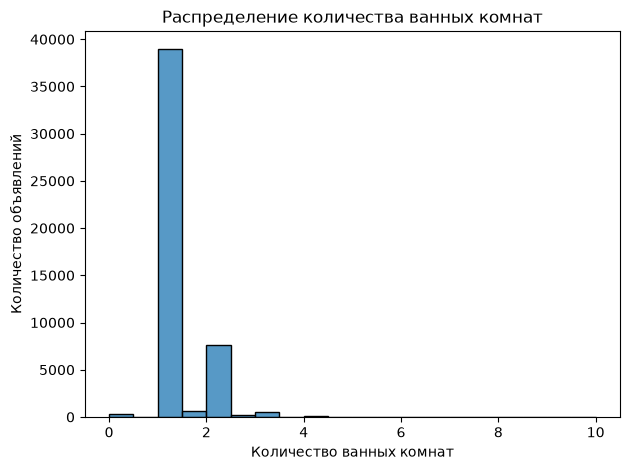

In [139]:
sns.histplot(
    data=data_clean,
    x="bathrooms", 
    binwidth=0.5   
)

plt.title("Распределение количества ванных комнат")
plt.xlabel("Количество ванных комнат")
plt.ylabel("Количество объявлений")
plt.tight_layout()
plt.show()


### Выводы по распределениям спален и ванных комнат

Чаще всего встречаются объявления с одной спальней (15 540) и двумя спальнями (14 546).
Нулевое количество спален встречается в 9 201 объявлении и может соответствовать студиям.
Большое количество спален встречается редко: например, 7 спален указано в одном объявлении, 8 спален в двух.

Для ванных комнат наиболее распространено значение 1 (38 928 объявлений), затем 2 (7 580 объявлений).
Встречаются дробные значения, например 1,5 и 2,5.
Есть редкие крайние значения, включая 10 ванных комнат в одном объявлении, а также 302 объявления с нулевым значением.
Такие записи являются кандидатами для дополнительной проверки, но редкость значения сама по себе не доказывает ошибку.

Фильтрация по цене не гарантирует отсутствия необычных значений других признаков.

### Совместный анализ признаков и цены

Далее рассчитаем корреляции для `bathrooms`, `bedrooms`, `interest_level_encoded` и `price` на очищенной выборке и отобразим их на тепловой карте.


In [140]:
corr_matrix = data_clean.corr(numeric_only=True)
corr_matrix

,bathrooms,bedrooms,price,interest_level_encoded
bathrooms,1.000000,0.517574,0.671943,-0.063635
bedrooms,0.517574,1.000000,0.545948,0.050654
price,0.671943,0.545948,1.000000,-0.200111
interest_level_encoded,-0.063635,0.050654,-0.200111,1.000000


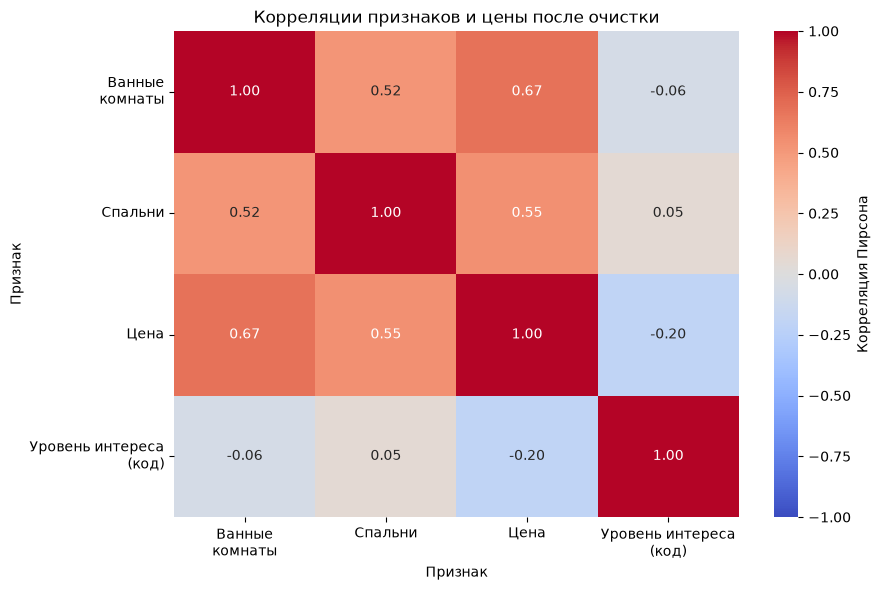

In [141]:
plt.figure(figsize=(9, 6))
labels = ["Ванные\nкомнаты", "Спальни", "Цена", "Уровень интереса\n(код)"]

sns.heatmap(
    data=corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={"label": "Корреляция Пирсона"}
)

plt.title("Корреляции признаков и цены после очистки")
plt.xlabel("Признак")
plt.ylabel("Признак")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Выводы по корреляционной матрице после очистки

На очищенной выборке цена имеет положительную линейную связь с количеством ванных комнат (около 0,672) и спален (около 0,546).
Из этих двух признаков более высокая корреляция с ценой наблюдается у количества ванных комнат.
Ванные комнаты и спальни также положительно связаны между собой: корреляция составляет около 0,518.

| Пара признаков | До очистки цены | После очистки цены |
|---|---:|---:|
| Цена и ванные комнаты | 0,070 | 0,672 |
| Цена и спальни | 0,052 | 0,546 |

После исключения крайних цен коэффициенты стали существенно выше. Это показывает, что экстремальные значения сильно влияли на оценку линейной связи в исходной выборке.

Корреляция цены с кодом уровня интереса составляет около -0,200.
При кодировании low=0, medium=1, high=2 это соответствует слабой отрицательной линейной связи: более дорогие объявления в среднем связаны с более низким уровнем интереса.
Вывод зависит от выбранного числового представления упорядоченных категорий.

Корреляция описывает связь, но не доказывает причинность и сама по себе не определяет качество будущей модели. Качество проверим на тестовой выборке.


### Диаграммы рассеяния признаков и цены

На оси X каждого графика расположена стоимость аренды, на оси Y один из исследуемых признаков.
Каждая точка соответствует одному объявлению очищенной выборки.
Небольшой размер и прозрачность точек помогают различать области их скопления.


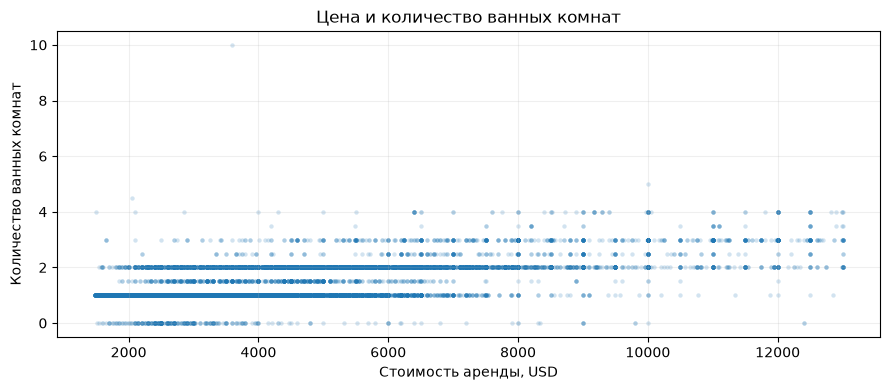

In [142]:
plt.figure(figsize=(9, 4))
sns.scatterplot(
    data=data_clean,
    x="price",
    y="bathrooms",
    alpha=0.2,
    s=10,
    linewidth=0
)

plt.title("Цена и количество ванных комнат")
plt.xlabel("Стоимость аренды, USD")
plt.ylabel("Количество ванных комнат")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


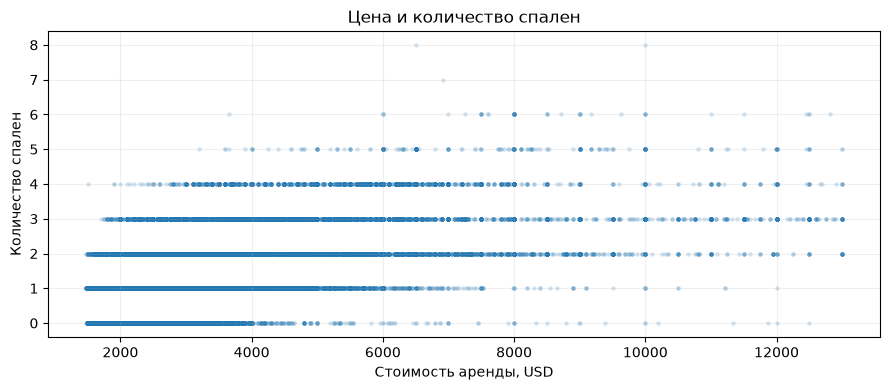

In [143]:
plt.figure(figsize=(9, 4))
sns.scatterplot(
    data=data_clean,
    x="price",
    y="bedrooms",
    alpha=0.2,
    s=10,
    linewidth=0
)

plt.title("Цена и количество спален")
plt.xlabel("Стоимость аренды, USD")
plt.ylabel("Количество спален")
plt.yticks(range(int(data_clean["bedrooms"].max()) + 1))
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


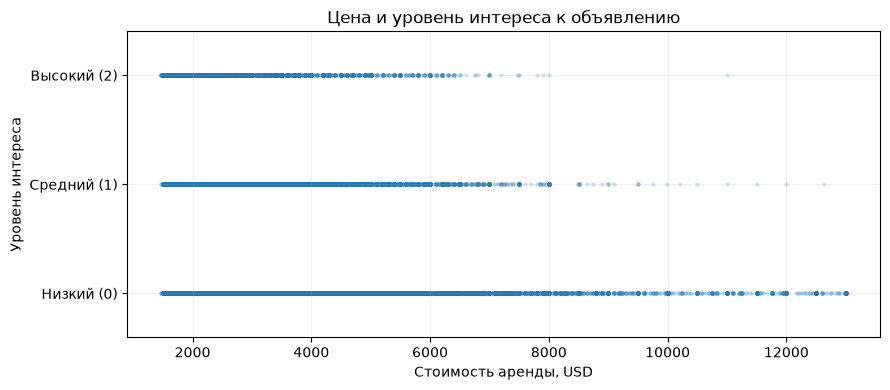

In [144]:
plt.figure(figsize=(9, 4))
sns.scatterplot(
    data=data_clean,
    x="price",
    y="interest_level_encoded",
    alpha=0.2,
    s=10,
    linewidth=0
)

plt.title("Цена и уровень интереса к объявлению")
plt.xlabel("Стоимость аренды, USD")
plt.ylabel("Уровень интереса")
plt.yticks([0, 1, 2], ["Низкий (0)", "Средний (1)", "Высокий (2)"])
plt.ylim(-0.4, 2.4)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Выводы по диаграммам рассеяния

Горизонтальные полосы возникают из-за ограниченного набора значений признаков: количества комнат и трёх уровней интереса.

При увеличении числа спален и ванных комнат объявления в целом смещаются в сторону более высоких цен.
При этом диапазоны цен сильно перекрываются: квартиры с одинаковым количеством комнат могут заметно различаться по стоимости аренды.
Это согласуется с положительными корреляциями, но показывает, что цена не определяется числом комнат однозначно.

Для уровня интереса наблюдается обратная тенденция: высокий интерес чаще связан с более низкими ценами.
Медианная цена в группе high составляет 2 500 USD, в группе medium 2 895 USD, в группе low 3 300 USD.
Между группами также есть значительное перекрытие цен. Разная плотность точек частично связана с неравным количеством объявлений в категориях.

На графиках сохраняются редкие необычные сочетания, например большое количество ванных комнат при сравнительно невысокой цене.
Очистка по процентилям цены не исключает все возможные аномалии других признаков.
Эти наблюдения описывают очищенную выборку и не доказывают причинно-следственную связь.


## 4. Создание признаков

### Квадраты исходных признаков

Добавим квадраты количества ванных комнат, количества спален и числового кода уровня интереса.
Возведение в квадрат является примером преобразования, которое может помочь описать нелинейную зависимость цены от признака.
Сравним корреляции исходных и преобразованных признаков с ценой на очищенной выборке.

Для уровня интереса используем `interest_level_encoded`, поскольку исходный `interest_level` содержит строки.
Квадрат кода категории является учебным примером и зависит от выбранного соответствия категорий числам.

Этот эксперимент входит в обязательную часть задания. При дальнейшем обучении по условию будем использовать только признаки на основе `bathrooms` и `bedrooms`.


In [145]:
data_clean["bathrooms_squared"] = data_clean["bathrooms"]**2
data_clean["bedrooms_squared"] = data_clean["bedrooms"]**2
data_clean["interest_level_squared"] = data_clean["interest_level_encoded"]**2
data_clean.head()

,bathrooms,bedrooms,interest_level,price,interest_level_encoded,bathrooms_squared,bedrooms_squared,interest_level_squared
4,1.0,1,medium,2400,1,1.00,1,1
6,1.0,2,low,3800,0,1.00,4,0
9,1.0,2,medium,3495,1,1.00,4,1
10,1.5,3,medium,3000,1,2.25,9,1
15,1.0,0,low,2795,0,1.00,0,0


In [146]:
corr_matrix_features = data_clean.corr(numeric_only=True)
corr_matrix_features["price"]

bathrooms                 0.671943
bedrooms                  0.545948
price                     1.000000
interest_level_encoded   -0.200111
bathrooms_squared         0.648486
bedrooms_squared          0.543406
interest_level_squared   -0.182672
Name: price, dtype: float64

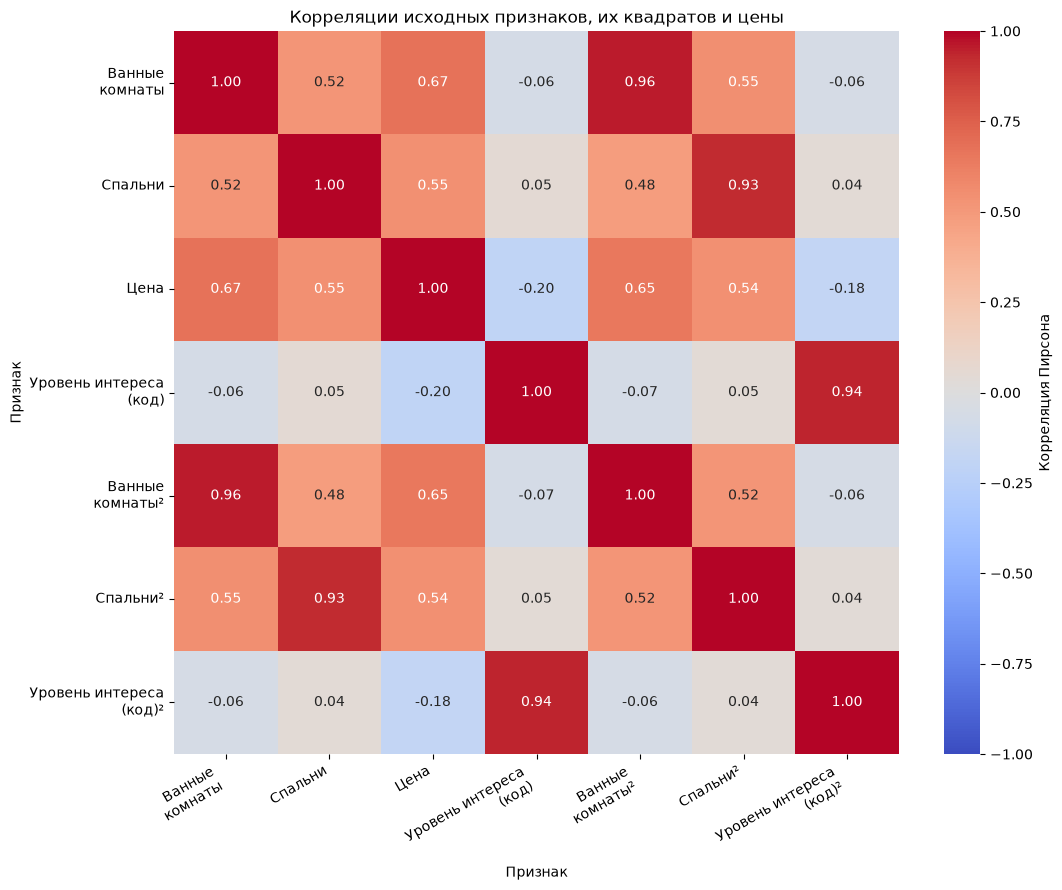

In [147]:
feature_labels = {
    "bathrooms": "Ванные\nкомнаты",
    "bedrooms": "Спальни",
    "price": "Цена",
    "interest_level_encoded": "Уровень интереса\n(код)",
    "bathrooms_squared": "Ванные\nкомнаты²",
    "bedrooms_squared": "Спальни²",
    "interest_level_squared": "Уровень интереса\n(код)²"
}

plt.figure(figsize=(11, 9))
sns.heatmap(
    data=corr_matrix_features,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=[feature_labels[column] for column in corr_matrix_features.columns],
    yticklabels=[feature_labels[column] for column in corr_matrix_features.index],
    cbar_kws={"label": "Корреляция Пирсона"}
)

plt.title("Корреляции исходных признаков, их квадратов и цены")
plt.xlabel("Признак")
plt.ylabel("Признак")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Сравнение исходных признаков и их квадратов

| Исходный признак | Корреляция с ценой | Корреляция квадрата с ценой |
|---|---:|---:|
| `bathrooms` | 0,672 | 0,648 |
| `bedrooms` | 0,546 | 0,543 |
| `interest_level_encoded` | -0,200 | -0,183 |

Для всех трёх признаков после возведения в квадрат абсолютная величина корреляции с ценой немного уменьшилась.
Следовательно, в этом эксперименте квадраты не показали более сильной линейной связи с ценой, чем исходные признаки.
Для уровня интереса сравниваем модули отрицательных коэффициентов: 0,183 меньше 0,200.

Парная корреляция сама по себе не определяет полезность признака в модели: несколько признаков могут работать совместно.
Согласно заданию, созданные вручную квадраты остаются частью исследования. Далее для обучения используем только признаки на основе количества ванных комнат и спален.


### Разделение на обучающую и тестовую выборки

Для обучения используем два исходных признака: `bathrooms` и `bedrooms`. Целевая переменная - `price`.
Матрицу признаков обозначим `X`, столбец целевых значений `y`.

После загрузки `test.json` доступны две исходные выборки Kaggle:
- `train.json`: 49 352 объявления и 15 столбцов;
- `test.json`: 74 659 объявлений и 14 столбцов.

Объявления в файлах не пересекаются по `listing_id`; повторяющихся `listing_id` внутри каждого файла нет.
В `test.json` отсутствует `interest_level`, но присутствуют `bathrooms`, `bedrooms` и `price`. В этих трёх столбцах нет пропусков или бесконечных значений.
Поэтому файлы можно использовать как обучающую и тестовую выборки для нашей задачи регрессии цены без дополнительного случайного разбиения 80/20.
Это рабочая интерпретация неоднозначного пункта README: точные имена подготовленных авторами файлов там не указаны.

Для обучающей выборки уже выполнена очистка цены по 1-му и 99-му процентилям: сохранён диапазон 1 475-13 000 USD и 48 379 объявлений.
Перед оценкой модели отдельно зафиксируем правило подготовки тестовой выборки. При применении того же диапазона цен в ней останется 73 255 объявлений; это будет оценка качества только для указанного диапазона аренды.

В тестовой выборке также найдены три объявления с количеством ванных комнат за диапазоном обучающих данных: два со значением 20 и одно со значением 112.
Эти записи требуют рассмотрения перед полиномиальным преобразованием степени 10. Автоматически исправлять их по предположению нельзя.

Полиномиальное преобразование выполняем раздельно: `fit_transform` для обучающих признаков и `transform` для тестовых.


In [148]:
test_df = pd.read_json('./data/test.json')
test_df.shape

(74659, 14)

In [149]:
test_data = test_df[["bathrooms","bedrooms","price"]].copy()
test_clean = test_data[test_data["price"].between(lower,upper)].copy()

In [150]:
test_clean.shape

(73255, 3)

In [151]:
print(test_clean["price"].min())
print(test_clean["price"].max())

1475
13000


### Результат подготовки тестовой выборки по цене

Исходная таблица `test_df` содержит 74 659 строк и 14 столбцов.
Для регрессии выбраны `bathrooms`, `bedrooms` и `price`.

К тестовым ценам применены границы 1 475 и 13 000 USD, ранее рассчитанные по обучающей выборке.
Обе границы включены в диапазон. После фильтрации таблица `test_clean` содержит 73 255 строк и 3 столбца.
Исключено 1 404 объявления. Минимальная оставшаяся цена равна 1 475 USD, максимальная 13 000 USD.

Таким образом, итоговые метрики будут описывать качество для объявлений в указанном диапазоне цен.
В тестовых признаках сохраняются три необычных значения количества ванных комнат: 20, 112 и 20. Они требуют отдельного рассмотрения перед обучением.


In [152]:
test_clean[test_clean["bathrooms"] > 10]

,bathrooms,bedrooms,price
837,20.0,3,5000
17808,112.0,3,3700
22737,20.0,2,4900


### Необычные значения тестовых признаков

В тестовой выборке найдены три объявления с количеством ванных комнат больше максимума обучающей выборки (10):

| Индекс | Ванные комнаты | Спальни | Цена, USD |
|---|---:|---:|---:|
| 837 | 20 | 3 | 5 000 |
| 17808 | 112 | 3 | 3 700 |
| 22737 | 20 | 2 | 4 900 |

В описании объявления с индексом 22737 явно указаны две ванные комнаты, что подтверждает ошибку в числовом поле. Для остальных двух записей точное исправление по описанию не установлено.

В основном эксперименте сохраняем все объявления, прошедшие установленную фильтрацию цены. Дополнительную фильтрацию по количеству комнат не вводим, значения вручную не исправляем.
Таким образом, результаты будут включать влияние этих необычных тестовых признаков. Это особенно важно при интерпретации полиномиальной модели степени 10, чувствительной к значениям за пределами обучающего диапазона.

### Подготовка матриц признаков и целевых значений

Из `data_clean` формируем обучающую выборку, из `test_clean` тестовую.
Для обеих матриц признаков используем одинаковые столбцы в одинаковом порядке: `bathrooms`, `bedrooms`.
Целевая переменная для обеих выборок находится в столбце `price`.


In [153]:
X_train = data_clean[["bathrooms", "bedrooms"]]
X_test = test_clean[["bathrooms","bedrooms"]]
y_train = data_clean["price"]
y_test = test_clean["price"]

### Полиномиальное преобразование степени 10

По условию задания применяем `PolynomialFeatures` со степенью 10 к двум исходным признакам: `bathrooms` и `bedrooms`.
Преобразование создаёт степени и произведения признаков с общей степенью не выше 10.
Например, при степени 2 из двух признаков a и b получаются столбцы 1, a, b, a², ab, b².

При степени 10 и двух исходных признаках по умолчанию получим 66 столбцов, включая постоянный столбец единиц.
Объект преобразования создаём один раз. К `X_train` применяем `fit_transform`, к `X_test` метод `transform` того же объекта.
Результаты сохраняем отдельно как `X_train_poly` и `X_test_poly`.
Целевые значения `y_train` и `y_test` остаются ценами аренды и не подвергаются этому преобразованию.


In [154]:
poly = PolynomialFeatures(degree=10)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(X_train_poly.shape, X_test_poly.shape)

(48379, 66) (73255, 66)


## 5. Обучение и сравнение моделей

### Таблицы результатов и метрики

Создадим две таблицы: `result_MAE` и `result_RMSE`, со столбцами `model`, `train`, `test`.
Для каждого подхода будем отдельно оценивать ошибки на обучающей и тестовой выборках.

MAE является средним абсолютным отклонением прогноза от фактической цены.
RMSE является квадратным корнем из среднего квадрата ошибок и сильнее реагирует на большие отклонения.
Обе метрики выражены в тех же единицах, что и цена, то есть в USD. Чем меньше значение, тем точнее прогноз по соответствующей метрике.

В таблицах сравним `linear_regression`, `decision_tree`, `naive_mean` и `naive_median`.
Качество на train показывает соответствие обучающим данным; основное сравнение качества на новых объявлениях проводим по test.


In [155]:
result_MAE = pd.DataFrame(columns=["model","train","test"])
result_RMSE = pd.DataFrame(columns=["model","train","test"])



### Линейная регрессия

Создадим `LinearRegression` со стандартными параметрами, как требуется в задании.
Модель обучаем на `X_train_poly` и `y_train`.
Для предсказаний на обучающих и тестовых объявлениях используем соответствующие преобразованные матрицы `X_train_poly` и `X_test_poly`.

Предсказанные цены сохраним в столбец `linear_prediction` таблиц `data_clean` и `test_clean`.
Затем рассчитаем MAE и RMSE отдельно для train и test и добавим результаты в таблицы сравнения.


In [156]:
linear_model = LinearRegression()
linear_model.fit(X_train_poly, y_train)
data_clean["linear_prediction"] = linear_model.predict(X_train_poly)
test_clean["linear_prediction"] = linear_model.predict(X_test_poly)

In [157]:
data_clean[["price","linear_prediction"]].head()

,price,linear_prediction
4,2400,3083.791652
6,3800,3209.193305
9,3495,3209.193305
10,3000,4082.424758
15,2795,3074.537396


In [158]:
test_clean[["price","linear_prediction"]].head()

,price,linear_prediction
0,2950,3083.791652
1,2850,3209.193305
2,2295,3074.537396
3,2900,3209.193305
5,3254,3083.791652


In [159]:
mae_train_linear = mean_absolute_error(y_train, data_clean["linear_prediction"])
mae_test_linear = mean_absolute_error(y_test, test_clean["linear_prediction"])
rmse_train_linear = root_mean_squared_error(y_train, data_clean["linear_prediction"])
rmse_test_linear = root_mean_squared_error(y_test, test_clean["linear_prediction"])

print(f"MAE на train: {mae_train_linear:.6g} USD")
print(f"MAE на test: {mae_test_linear:.6g} USD")
print(f"RMSE на train: {rmse_train_linear:.6g} USD")
print(f"RMSE на test: {rmse_test_linear:.6g} USD")


MAE на train: 855.149 USD
MAE на test: 9.20137e+13 USD
RMSE на train: 1218.49 USD
RMSE на test: 2.49041e+16 USD


In [160]:
result_MAE.loc[0] = ["linear_regression", mae_train_linear, mae_test_linear]
result_RMSE.loc[0] = ["linear_regression", rmse_train_linear, rmse_test_linear]

print("MAE, USD:")
display(result_MAE)
print("RMSE, USD:")
display(result_RMSE)


MAE, USD:


,model,train,test
0,linear_regression,855.148649,9.201365e+13


RMSE, USD:


,model,train,test
0,linear_regression,1218.486089,2.490410e+16


### Результаты линейной регрессии

На обучающей выборке MAE составляет около 855,15 USD, RMSE около 1 218,49 USD.
На тестовой выборке MAE достигает примерно 9,20 × 10¹³ USD, RMSE примерно 2,49 × 10¹⁶ USD.

Почти вся абсолютная ошибка на test приходится на три ранее найденных объявления с 20 и 112 ванными комнатами.
Например, для объявления с 112 ванными комнатами и фактической ценой 3 700 USD модель предсказывает около 6,74 × 10¹⁸ USD.
При степени 10 признаки принимают очень большие значения за пределами обучающего диапазона. Полиномиальная модель в этом эксперименте крайне неустойчива к такой экстраполяции.

Большая тестовая ошибка не вызвана перестановкой аргументов метрик: реальные цены и прогнозы сопоставлены правильно.
Для основного сравнения сохраняем все тестовые объявления, прошедшие установленную фильтрацию цены. Остальные подходы будем оценивать на той же выборке.


### Дерево решений

По условию задания используем `DecisionTreeRegressor` с `random_state=21`, остальные параметры оставляем стандартными.
Для сопоставимости обучаем дерево на той же матрице `X_train_poly` и тех же целевых значениях `y_train`.
Предсказания для train и test сохраняем в столбец `tree_prediction` соответствующих таблиц.

Дерево разделяет объекты по условиям на признаки. При стандартном критерии прогноз в листе равен среднему значению обучающих цен объектов этого листа.
Такой способ прогнозирования не продолжает полиномиальную кривую за пределы обучающих данных, хотя сами входные признаки у нас полиномиальные.
Проверим качество с помощью тех же MAE и RMSE на тех же обучающей и тестовой выборках.


In [161]:
tree_model = DecisionTreeRegressor(random_state=21)
tree_model.fit(X_train_poly, y_train)

data_clean["tree_prediction"] = tree_model.predict(X_train_poly)
test_clean["tree_prediction"] = tree_model.predict(X_test_poly)


In [162]:
print("Обучающая выборка:")
display(data_clean[["price", "tree_prediction"]].head())
print("Тестовая выборка:")
display(test_clean[["price", "tree_prediction"]].head())


Обучающая выборка:


,price,tree_prediction
4,2400,3038.673625
6,3800,3202.066470
9,3495,3202.066470
10,3000,4100.918269
15,2795,2478.608522


Тестовая выборка:


,price,tree_prediction
0,2950,3038.673625
1,2850,3202.066470
2,2295,2478.608522
3,2900,3202.066470
5,3254,3038.673625


In [163]:
mae_train_tree = mean_absolute_error(y_train, data_clean["tree_prediction"])
mae_test_tree = mean_absolute_error(y_test, test_clean["tree_prediction"])
rmse_train_tree = root_mean_squared_error(y_train, data_clean["tree_prediction"])
rmse_test_tree = root_mean_squared_error(y_test, test_clean["tree_prediction"])

print(f"MAE на train: {mae_train_tree:.2f} USD")
print(f"MAE на test: {mae_test_tree:.2f} USD")
print(f"RMSE на train: {rmse_train_tree:.2f} USD")
print(f"RMSE на test: {rmse_test_tree:.2f} USD")


MAE на train: 756.04 USD
MAE на test: 759.76 USD
RMSE на train: 1077.48 USD
RMSE на test: 1081.75 USD


In [164]:
result_MAE.loc[1] = ["decision_tree", mae_train_tree, mae_test_tree]
result_RMSE.loc[1] = ["decision_tree", rmse_train_tree, rmse_test_tree]

print("MAE, USD:")
display(result_MAE)
print("RMSE, USD:")
display(result_RMSE)


MAE, USD:


,model,train,test
0,linear_regression,855.148649,9.201365e+13
1,decision_tree,756.044735,7.597629e+02


RMSE, USD:


,model,train,test
0,linear_regression,1218.486089,2.490410e+16
1,decision_tree,1077.483596,1.081755e+03


### Результаты дерева решений

| Метрика | Train, USD | Test, USD |
|---|---:|---:|
| MAE | 756,04 | 759,76 |
| RMSE | 1 077,48 | 1 081,75 |

По обеим тестовым метрикам дерево показало меньшую ошибку, чем ранее обученная линейная регрессия на полиномиальных признаках.
Прогнозы дерева остаются в пределах обучающих цен. Для необычных тестовых значений количества ванных комнат оно не выдаёт гигантских прогнозов, возникших у полиномиальной линейной модели.

Оценка выполнена на тех же 73 255 тестовых объявлениях, включая три записи с 20 и 112 ванными комнатами.
Далее сравним обе модели с наивными прогнозами по среднему и медиане обучающих цен.


### Наивные модели

Сравним обученные модели с двумя простыми подходами:
- `naive_mean`: всем объявлениям предсказываем среднюю цену обучающей выборки;
- `naive_median`: всем объявлениям предсказываем медианную цену обучающей выборки.

Каждый подход выдаёт одну и ту же цену независимо от количества комнат.
Среднее и медиану вычисляем только по `y_train`. Эти же две константы используем для прогнозов на train и test.
В README формулировка о средних и медианах обеих выборок неоднозначна. Для честной тестовой оценки цены тестовых объявлений не используем для выбора прогнозируемой константы.

Такие прогнозы являются базовым ориентиром: проверим, насколько обученные модели полезнее простого предсказания одной цены для всех квартир.
Среднее минимизирует сумму квадратов ошибок на обучающей выборке, а медиана минимизирует сумму абсолютных ошибок для постоянного прогноза.


In [165]:
mean_price = y_train.mean()
median_price = y_train.median()
print(mean_price, median_price)

3538.6368879059096 3150.0


In [166]:
data_clean["naive_mean_prediction"] = mean_price
data_clean["naive_median_prediction"] = median_price

test_clean["naive_mean_prediction"] = mean_price
test_clean["naive_median_prediction"] = median_price


In [167]:
print("Обучающая выборка:")
display(data_clean[["price", "naive_mean_prediction", "naive_median_prediction"]].head())
print("Тестовая выборка:")
display(test_clean[["price", "naive_mean_prediction", "naive_median_prediction"]].head())


Обучающая выборка:


,price,naive_mean_prediction,naive_median_prediction
4,2400,3538.636888,3150.0
6,3800,3538.636888,3150.0
9,3495,3538.636888,3150.0
10,3000,3538.636888,3150.0
15,2795,3538.636888,3150.0


Тестовая выборка:


,price,naive_mean_prediction,naive_median_prediction
0,2950,3538.636888,3150.0
1,2850,3538.636888,3150.0
2,2295,3538.636888,3150.0
3,2900,3538.636888,3150.0
5,3254,3538.636888,3150.0


In [168]:
mae_train_mean = mean_absolute_error(y_train, data_clean["naive_mean_prediction"])
mae_test_mean = mean_absolute_error(y_test, test_clean["naive_mean_prediction"])
rmse_train_mean = root_mean_squared_error(y_train, data_clean["naive_mean_prediction"])
rmse_test_mean = root_mean_squared_error(y_test, test_clean["naive_mean_prediction"])

In [169]:
mae_train_median = mean_absolute_error(y_train, data_clean["naive_median_prediction"])
mae_test_median = mean_absolute_error(y_test, test_clean["naive_median_prediction"])
rmse_train_median = root_mean_squared_error(y_train, data_clean["naive_median_prediction"])
rmse_test_median = root_mean_squared_error(y_test, test_clean["naive_median_prediction"])

print(f"MAE на train: {mae_train_median:.2f} USD")
print(f"MAE на test: {mae_test_median:.2f} USD")
print(f"RMSE на train: {rmse_train_median:.2f} USD")
print(f"RMSE на test: {rmse_test_median:.2f} USD")


MAE на train: 1086.21 USD
MAE на test: 1084.59 USD
RMSE на train: 1644.24 USD
RMSE на test: 1635.40 USD


In [170]:
result_MAE.loc[2] = ["naive_mean", mae_train_mean, mae_test_mean]
result_MAE.loc[3] = ["naive_median", mae_train_median, mae_test_median]

result_RMSE.loc[2] = ["naive_mean", rmse_train_mean, rmse_test_mean]
result_RMSE.loc[3] = ["naive_median", rmse_train_median, rmse_test_median]

print("Итоговая таблица MAE, USD:")
display(result_MAE)
print("Итоговая таблица RMSE, USD:")
display(result_RMSE)

best_mae_model = result_MAE.loc[result_MAE["test"].idxmin(), "model"]
best_rmse_model = result_RMSE.loc[result_RMSE["test"].idxmin(), "model"]
print(f"Лучший подход по тестовой MAE: {best_mae_model}")
print(f"Лучший подход по тестовой RMSE: {best_rmse_model}")


Итоговая таблица MAE, USD:


,model,train,test
0,linear_regression,855.148649,9.201365e+13
1,decision_tree,756.044735,7.597629e+02
2,naive_mean,1139.192515,1.137832e+03
3,naive_median,1086.210505,1.084588e+03


Итоговая таблица RMSE, USD:


,model,train,test
0,linear_regression,1218.486089,2.490410e+16
1,decision_tree,1077.483596,1.081755e+03
2,naive_mean,1597.646655,1.590391e+03
3,naive_median,1644.236439,1.635396e+03


Лучший подход по тестовой MAE: decision_tree
Лучший подход по тестовой RMSE: decision_tree


## 6. Итоговые выводы

Мы сравнили линейную регрессию на полиномиальных признаках степени 10, дерево решений и два постоянных прогноза по среднему и медиане обучающих цен.

Лучший результат среди четырёх подходов показало дерево решений:
- MAE на test: 759,76 USD;
- RMSE на test: 1 081,75 USD.

У дерева ошибки на обучающей и тестовой выборках близки. Для исследованных данных большого разрыва между train и test не наблюдается.

Среди постоянных прогнозов медиана дала меньшую тестовую MAE (1 084,59 USD), а среднее меньшую тестовую RMSE (1 590,39 USD).
Дерево снизило MAE примерно на 29,9% относительно медианного прогноза и RMSE примерно на 32,0% относительно прогноза по среднему.

Линейная регрессия на признаках степени 10 оказалась неустойчивой на тестовых объявлениях с 20 и 112 ванными комнатами. Эти записи дают почти всю её абсолютную тестовую ошибку.
Таким образом, более сложное преобразование признаков само по себе не гарантирует лучшего качества.

В основном эксперименте использованы два исходных признака: количество спален и ванных комнат. Среднее и медиана вычислены только по train, полиномиальное преобразование настроено на train и применено к test.
Метрики относятся к объявлениям с ценами от 1 475 до 13 000 USD включительно. Проверка выполнена на 73 255 объявлениях файла test.json; значения вне этого диапазона в оценку не вошли.
Разбиение по двум файлам Kaggle принято как рабочая интерпретация неоднозначного пункта README.

Проект показал полный цикл работы: исследование данных, очистку, создание признаков, обучение и сравнение моделей с простыми базовыми прогнозами.
